# 05. Selección del modelo y Model Registry — OralSolutions

**Objetivo.** Recuperar los tres modelos ajustados en `04_tuning.ipynb`, seleccionar **dos finalistas usando exclusivamente CV temporal**, calibrar los umbrales de negocio con predicciones fuera de pliegue, evaluar **una sola vez** el hold-out y registrar `champion` / `challenger` en MLflow.

**Datos:** 1.195 observaciones de entrenamiento, 356 excluidas por maduración temporal y 826 reservadas para prueba. El conjunto de prueba no participa en la elección de modelo ni de umbral.

**Importante:** este notebook crea **una corrida final**. No ejecutes `Run All` nuevamente después de registrar los modelos: reutiliza la sección independiente de comprobación del final.

In [1]:
import sys
import subprocess
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (average_precision_score, precision_score, recall_score,
                                f1_score, roc_auc_score, confusion_matrix)

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.pipeline import (cargar_datos, obtener_datos_divididos, obtener_hash_datos,
                            FECHA_CORTE, FECHA_EVENTO, SEMILLA)

MLFLOW_URI = 'http://localhost:5000'
EXPERIMENTO = 'OralSolutions'
REGISTRY_NAME = 'oralsolutions-modelo'
HORIZONTE_DIAS = 60
COSTO_FN, COSTO_FP = 120.0, 3.0  # Supuestos operativos, no costos clínicos medidos
TASA_RESCATE = 0.35               # Hipótesis de efectividad, no estimación causal

mlflow.set_tracking_uri(MLFLOW_URI)
exp = mlflow.get_experiment_by_name(EXPERIMENTO)
if exp is None:
    raise RuntimeError('No existe OralSolutions; ejecuta notebooks 03 y 04 antes.')
mlflow.set_experiment(EXPERIMENTO)
client = MlflowClient(tracking_uri=MLFLOW_URI)

HASH_DATOS = obtener_hash_datos()
X_train, X_test, y_train, y_test = obtener_datos_divididos()
base = cargar_datos()
limite_train = pd.Timestamp(FECHA_CORTE) - pd.Timedelta(days=HORIZONTE_DIAS)
fechas_train = base.loc[base[FECHA_EVENTO] <= limite_train, FECHA_EVENTO].reset_index(drop=True)
assert len(fechas_train) == len(X_train)

corridas = mlflow.search_runs(experiment_ids=[exp.experiment_id])
if ((corridas.get('tags.fase', pd.Series(index=corridas.index, dtype=object)) == 'final')
    & (corridas.get('params.hash_dataset', pd.Series(index=corridas.index, dtype=object)) == HASH_DATOS)).any():
    raise RuntimeError('Ya existe una corrida final para este dataset. No repitas la selección.')

padres = corridas.loc[
    corridas['tags.fase'].eq('tuning') &
    corridas['params.hash_dataset'].eq(HASH_DATOS) &
    corridas['metrics.pr_auc_cv_mean'].notna()
].copy()
padres = padres.sort_values('start_time', ascending=False).drop_duplicates('tags.mlflow.runName')
padres = padres.sort_values('metrics.pr_auc_cv_mean', ascending=False)
if len(padres) != 3:
    raise ValueError(f'Se esperaban 3 corridas padre de tuning, hay {len(padres)}.')
ranking = padres[['run_id','tags.mlflow.runName','metrics.pr_auc_cv_mean',
                    'metrics.pr_auc_cv_std','metrics.segundos_entrenamiento']].copy()
display(ranking)
print('Dataset SHA-256:', HASH_DATOS)
print('Finalistas:', padres['tags.mlflow.runName'].head(2).tolist())

=== DIVISIÓN TEMPORAL ===
Fecha de corte       : 2025-08-01
Horizonte            : 60 días
Límite entrenamiento : 2025-06-02
Train                : 1,195
Hold-out             : 826
Gap excluido         : 356


,run_id,tags.mlflow.runName,metrics.pr_auc_cv_mean,metrics.pr_auc_cv_std,metrics.segundos_entrenamiento
92,303bbd6f5077416682f5c065d6a0df1d,Tuning_MLPClassifier,0.188618,0.035175,20.648898
61,486b59d719de482aac58607cbce9d2c9,Tuning_HistGradientBoosting,0.185223,0.059669,15.313868
30,3faa7b3bfa2644ec8e41294909a9ff49,Tuning_LogisticRegression,0.182929,0.020221,4.946471


Dataset SHA-256: 11ae3cc53264511ef486f12d7a3fc0ddf2c6311e3ae7a8076f3c0cf046396dc1
Finalistas: ['Tuning_MLPClassifier', 'Tuning_HistGradientBoosting']


## 1. Dos finalistas y pliegues temporales

Se toman los dos mejores promedios de PR-AUC del tuning, sin mirar el hold-out. Se reconstruyen los **mismos cinco pliegues temporales** y la **purga de 60 días** del notebook 04; las predicciones fuera de pliegue (OOF) permitirán ajustar umbrales sin usar prueba.

In [2]:
fechas_unicas = pd.Index(fechas_train.drop_duplicates().sort_values())
cv_temporal = []
for i, (_, iv) in enumerate(TimeSeriesSplit(n_splits=5).split(fechas_unicas), 1):
    inicio_val, fin_val = fechas_unicas[iv[0]], fechas_unicas[iv[-1]]
    it = np.flatnonzero((fechas_train <= inicio_val - pd.Timedelta(days=HORIZONTE_DIAS)).to_numpy())
    ix = np.flatnonzero(((fechas_train >= inicio_val) & (fechas_train <= fin_val)).to_numpy())
    if not len(it) or not len(ix) or y_train.iloc[ix].nunique() < 2:
        raise ValueError(f'Pliegue {i} no válido')
    cv_temporal.append((it, ix))

finalistas = {}
filas_cv = []
for _, fila in padres.head(2).iterrows():
    nombre = fila['tags.mlflow.runName']
    rid = fila['run_id']
    modelo = mlflow.sklearn.load_model(f'runs:/{rid}/model')
    oof = np.full(len(y_train), np.nan)
    fold_scores = []
    for k, (it, iv) in enumerate(cv_temporal, 1):
        fold = clone(modelo).fit(X_train.iloc[it], y_train.iloc[it])
        prob = fold.predict_proba(X_train.iloc[iv])[:, 1]
        score = average_precision_score(y_train.iloc[iv], prob)
        oof[iv] = prob
        fold_scores.append(score)
        filas_cv.append({'modelo': nombre, 'pliegue': k, 'n_train': len(it),
                            'n_val': len(iv), 'pr_auc': score})
    finalistas[nombre] = {'run_id_tuning': rid, 'modelo': modelo,
                            'oof': oof, 'cv_mean': float(np.mean(fold_scores)),
                            'cv_std': float(np.std(fold_scores)), 'fold_scores': fold_scores}

df_pliegues = pd.DataFrame(filas_cv)
display(df_pliegues.pivot(index='pliegue', columns='modelo', values='pr_auc'))
res_cv = df_pliegues.groupby('modelo')['pr_auc'].agg(['mean','std'])
display(res_cv)

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converge

modelo,Tuning_HistGradientBoosting,Tuning_MLPClassifier
pliegue,,
1,0.090008,0.154459
2,0.244446,0.177729
3,0.249776,0.242703
4,0.189022,0.215204
5,0.152861,0.152997


,mean,std
modelo,,
Tuning_HistGradientBoosting,0.185223,0.066712
Tuning_MLPClassifier,0.188618,0.039326


## 2. Umbral y costo de negocio, solo con validación

Se compara el costo estimado `120 × FN + 3 × FP` entre umbrales, usando **únicamente predicciones OOF**. Un FN representa abandono no alertado; un FP, contacto a quien habría continuado. Estos costos son supuestos, por lo que la política elegida debe compararse con la referencia **contactar a todos**. La tasa de rescate del 35 % se reporta solo como hipótesis para el balance, no como ganancia observada.

Se establece un umbral operativo mínimo del 1 % (0,01) para la generación de alertas. Los umbrales candidatos se evalúan mediante el costo estimado de errores sobre predicciones fuera de pliegue (OOF), seleccionando el de menor costo dentro del rango permitido, sin utilizar el conjunto de prueba.

In [7]:
def calcular_negocio(y, p, umbral):
    pred = (np.asarray(p) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()

    return {
        "umbral": float(umbral),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "costo_errores_usd": float(fn * COSTO_FN + fp * COSTO_FP),
        "balance_estimado_usd": float(
            tp * (COSTO_FN * TASA_RESCATE - COSTO_FP)
            - fp * COSTO_FP - fn * COSTO_FN
        ),
    }


# Umbral operativo mínimo establecido para OralSolutions
UMBRAL_MINIMO = 0.01

# Optimizar costos únicamente con umbrales desde el 1 %
umbrales = np.linspace(UMBRAL_MINIMO, 1.0, 100)

filas_umbrales = []

for nombre, f in finalistas.items():
    valido = ~np.isnan(f["oof"])

    for u in umbrales:
        resultado = calcular_negocio(
            y_train.iloc[np.flatnonzero(valido)],
            f["oof"][valido],
            u
        )
        filas_umbrales.append({"modelo": nombre, **resultado})

df_umbrales = pd.DataFrame(filas_umbrales)

# Mejor umbral por modelo: menor costo y, en empate,
# mayor umbral para evitar alertas innecesarias.
mejores_umbrales = (
    df_umbrales
    .sort_values(
        ["costo_errores_usd", "umbral"],
        ascending=[True, False]
    )
    .drop_duplicates("modelo")
    .reset_index(drop=True)
)

display(mejores_umbrales[
    ["modelo", "umbral", "costo_errores_usd",
        "precision", "recall", "balance_estimado_usd"]
])

# Selección del champion sin desempate alfabético
orden = list(finalistas)
a, b = orden

ventaja_cv = finalistas[a]["cv_mean"] - finalistas[b]["cv_mean"]
variacion = max(finalistas[a]["cv_std"], finalistas[b]["cv_std"])

costos = mejores_umbrales.set_index("modelo")["costo_errores_usd"]

if not np.isclose(costos[a], costos[b]):
    nombre_champion = min(orden, key=lambda n: costos[n])
    criterio = "Menor costo de negocio estimado en OOF"

else:
    nombre_champion = max(
        orden,
        key=lambda n: finalistas[n]["cv_mean"]
    )
    criterio = "Empate en costo OOF; mayor PR-AUC promedio en CV"

nombre_challenger = next(
    n for n in orden if n != nombre_champion
)

umbrales_modelo = dict(zip(
    mejores_umbrales["modelo"],
    mejores_umbrales["umbral"]
))

# Referencias de negocio para contextualizar la decisión
nombre_ref = nombre_champion
valido = ~np.isnan(finalistas[nombre_ref]["oof"])
y_oof = y_train.iloc[np.flatnonzero(valido)]

costo_todos = len(y_oof[y_oof == 0]) * COSTO_FP
costo_ninguno = len(y_oof[y_oof == 1]) * COSTO_FN

print("\n=== SELECCIÓN DEL MODELO ===")
print("Champion propuesto:", nombre_champion)
print("Challenger propuesto:", nombre_challenger)
print("Criterio:", criterio)
print(f"Diferencia PR-AUC CV: {ventaja_cv:.4f}")
print(f"Variación entre pliegues: {variacion:.4f}")

print("\n=== REFERENCIAS DE NEGOCIO (OOF) ===")
print(f"Contactar a todos: USD {costo_todos:,.2f}")
print(f"No contactar a nadie: USD {costo_ninguno:,.2f}")

,modelo,umbral,costo_errores_usd,precision,recall,balance_estimado_usd
0,Tuning_HistGradientBoosting,0.01,3459.0,0.140748,0.953333,2118.0
1,Tuning_MLPClassifier,0.01,5019.0,0.150179,0.840000,-105.0



=== SELECCIÓN DEL MODELO ===
Champion propuesto: Tuning_HistGradientBoosting
Challenger propuesto: Tuning_MLPClassifier
Criterio: Menor costo de negocio estimado en OOF
Diferencia PR-AUC CV: 0.0034
Variación entre pliegues: 0.0597

=== REFERENCIAS DE NEGOCIO (OOF) ===
Contactar a todos: USD 2,847.00
No contactar a nadie: USD 18,000.00


## 3. Evaluación final en hold-out (una sola vez)

A partir de este punto se abre el conjunto reservado: **826 observaciones** desde el 1 de agosto de 2025. Ambos modelos se evalúan en esas mismas filas con los umbrales seleccionados en OOF.

In [4]:
resultados_test = []
prob_test = {}
for nombre in [nombre_champion, nombre_challenger]:
    modelo = finalistas[nombre]['modelo']  # Ya entrenado con el conjunto histórico completo en notebook 04
    t0 = time.perf_counter()
    prob = modelo.predict_proba(X_test)[:, 1]
    latencia_ms = (time.perf_counter()-t0)*1000
    prob_test[nombre] = prob
    u = float(umbrales_modelo[nombre])
    resultados_test.append({
        'modelo': nombre,
        'rol': 'champion' if nombre == nombre_champion else 'challenger',
        'run_id_tuning': finalistas[nombre]['run_id_tuning'],
        'pr_auc_cv_mean': finalistas[nombre]['cv_mean'],
        'pr_auc_cv_std': finalistas[nombre]['cv_std'],
        'pr_auc_test': average_precision_score(y_test, prob),
        'roc_auc_test': roc_auc_score(y_test, prob),
        'inferencia_ms_lote': latencia_ms,
        **calcular_negocio(y_test, prob, u),
    })

df_test = pd.DataFrame(resultados_test)
display(df_test)
referencia_todos = calcular_negocio(y_test, np.ones(len(y_test)), 0.5)
print('Referencia contactar a todos (test):', referencia_todos)

,modelo,rol,run_id_tuning,pr_auc_cv_mean,pr_auc_cv_std,pr_auc_test,roc_auc_test,inferencia_ms_lote,umbral,TP,FP,FN,TN,precision,recall,f1,costo_errores_usd,balance_estimado_usd
0,Tuning_HistGradientBoosting,champion,486b59d719de482aac58607cbce9d2c9,0.185223,0.059669,0.159858,0.564182,10.0244,0.01,118,704,0,4,0.143552,1.000000,0.251064,2112.0,2490.0
1,Tuning_MLPClassifier,challenger,303bbd6f5077416682f5c065d6a0df1d,0.188618,0.035175,0.166552,0.561919,7.9572,0.01,114,646,4,62,0.150000,0.966102,0.259681,2418.0,2028.0


Referencia contactar a todos (test): {'umbral': 0.5, 'TP': 118, 'FP': 708, 'FN': 0, 'TN': 0, 'precision': 0.14285714285714285, 'recall': 1.0, 'f1': 0.25, 'costo_errores_usd': 2124.0, 'balance_estimado_usd': 2478.0}


## 4. Registrar modelos y preservar trazabilidad

La corrida final registra la decisión, sus métricas y el modelo `champion` con firma y ejemplo de entrada. El `challenger` se registra desde el artefacto ajustado del notebook 04. Los aliases apuntan a versiones del mismo modelo registrado `oralsolutions-modelo`.

In [5]:
commit = subprocess.run(['git','rev-parse','HEAD'], cwd=ROOT,
                        capture_output=True, text=True).stdout.strip() or 'sin_commit'

with mlflow.start_run(run_name='FINAL_OralSolutions') as run_final:
    mlflow.set_tags({'fase': 'final', 'familia': nombre_champion,
                        'git_commit': commit, 'eleccion': criterio})
    mlflow.log_params({'hash_dataset': HASH_DATOS, 'fecha_corte': FECHA_CORTE,
                        'horizonte_dias': HORIZONTE_DIAS, 'semilla': SEMILLA,
                        'tabla_origen': 'ORALSOLUTIONS_DW.OBT.OBT_RIESGO_ABANDONO + GOLD',
                        'modelo_champion': nombre_champion,
                        'modelo_challenger': nombre_challenger,
                        'run_id_tuning_champion': finalistas[nombre_champion]['run_id_tuning'],
                        'run_id_tuning_challenger': finalistas[nombre_challenger]['run_id_tuning'],
                        'umbral_negocio': float(umbrales_modelo[nombre_champion]),
                        'costo_fn': COSTO_FN, 'costo_fp': COSTO_FP})
    fila_final = df_test.loc[df_test['modelo'].eq(nombre_champion)].iloc[0]
    mlflow.log_metrics({
        'pr_auc_cv_mean': float(finalistas[nombre_champion]['cv_mean']),
        'pr_auc_cv_std': float(finalistas[nombre_champion]['cv_std']),
        'pr_auc_test': float(fila_final['pr_auc_test']),
        'roc_auc_test': float(fila_final['roc_auc_test']),
        'precision_test': float(fila_final['precision']),
        'recall_test': float(fila_final['recall']),
        'f1_test': float(fila_final['f1']),
        'costo_errores_test_usd': float(fila_final['costo_errores_usd']),
        'inferencia_ms_lote': float(fila_final['inferencia_ms_lote']),
    })
    mlflow.log_dict({'finalistas': __import__('json').loads(df_test.to_json(orient='records')),
                    'criterio': criterio, 'costos_son_estimaciones': True},
                    'decision.json')

    muestra_entrada = X_train.iloc[:5].copy()
    modelo_final = finalistas[nombre_champion]['modelo']
    # La firma corresponde a predict (comportamiento pyfunc por defecto).
    firma = infer_signature(muestra_entrada, modelo_final.predict(muestra_entrada))
    mlflow.sklearn.log_model(sk_model=modelo_final, artifact_path='model',
                            signature=firma, input_example=muestra_entrada)
    id_final = run_final.info.run_id

version_champ = mlflow.register_model(f'runs:/{id_final}/model', REGISTRY_NAME)
version_chall = mlflow.register_model(
    f"runs:/{finalistas[nombre_challenger]['run_id_tuning']}/model", REGISTRY_NAME)
client.set_registered_model_alias(REGISTRY_NAME, 'champion', version_champ.version)
client.set_registered_model_alias(REGISTRY_NAME, 'challenger', version_chall.version)
client.set_model_version_tag(REGISTRY_NAME, version_champ.version,
                            'umbral_decision', str(float(umbrales_modelo[nombre_champion])))
client.set_model_version_tag(REGISTRY_NAME, version_chall.version,
                            'umbral_decision', str(float(umbrales_modelo[nombre_challenger])))

print('Run final:', id_final)
print('Champion:', nombre_champion, '| versión', version_champ.version,
    '| umbral', umbrales_modelo[nombre_champion])
print('Challenger:', nombre_challenger, '| versión', version_chall.version,
    '| umbral', umbrales_modelo[nombre_challenger])

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run FINAL_OralSolutions at: http://localhost:5000/#/experiments/1/runs/c90a1c37aef940278afc025b1d22dc6b
🧪 View experiment at: http://localhost:5000/#/experiments/1


Successfully registered model 'oralsolutions-modelo'.
2026/11/23 20:12:42 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: oralsolutions-modelo, version 1
Created version '1' of model 'oralsolutions-modelo'.
Registered model 'oralsolutions-modelo' already exists. Creating a new version of this model...
2026/11/23 20:12:48 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: oralsolutions-modelo, version 2
Created version '2' of model 'oralsolutions-modelo'.


Run final: c90a1c37aef940278afc025b1d22dc6b
Champion: Tuning_HistGradientBoosting | versión 1 | umbral 0.01
Challenger: Tuning_MLPClassifier | versión 2 | umbral 0.01


## 5. Reproducibilidad y evidencias

Se comprueba que el `champion` cargado por alias reproduce exactamente su PR-AUC de prueba. Después se exportan **todas las corridas** de MLflow a `docs/corridas.csv` y una tabla resumen a `docs/resultados_seleccion.csv`.

PR-AUC test reproducida: 0.159858
Corridas exportadas: 102
Archivos: C:\Users\ANDRES\Desktop\proyecto_final\docs\corridas.csv C:\Users\ANDRES\Desktop\proyecto_final\docs\resultados_seleccion.csv


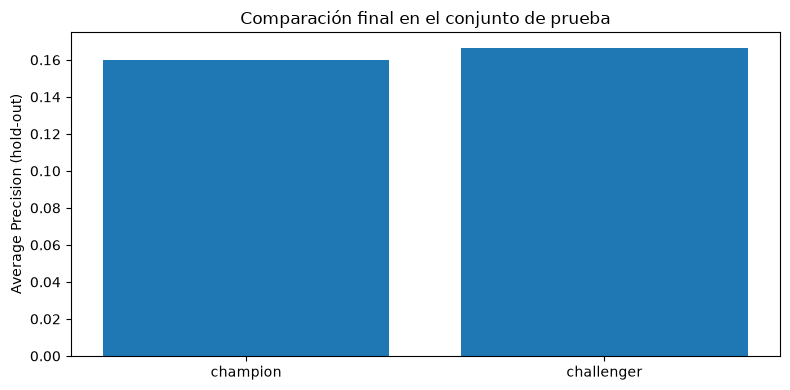

In [6]:
champion_cargado = mlflow.sklearn.load_model(f'models:/{REGISTRY_NAME}@champion')
ap_reproducida = average_precision_score(y_test, champion_cargado.predict_proba(X_test)[:, 1])
ap_registrada = float(client.get_run(id_final).data.metrics['pr_auc_test'])
assert np.isclose(ap_reproducida, ap_registrada, atol=1e-12), 'No se reproduce la métrica.'
print('PR-AUC test reproducida:', f'{ap_reproducida:.6f}')

ruta_docs = ROOT / 'docs'
ruta_docs.mkdir(parents=True, exist_ok=True)
df_test.to_csv(ruta_docs / 'resultados_seleccion.csv', index=False)
corridas_finales = mlflow.search_runs(experiment_ids=[exp.experiment_id],
                                        search_all_experiments=False, max_results=10000)
corridas_finales.to_csv(ruta_docs / 'corridas.csv', index=False)
print('Corridas exportadas:', len(corridas_finales))
print('Archivos:', ruta_docs / 'corridas.csv', ruta_docs / 'resultados_seleccion.csv')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df_test['rol'], df_test['pr_auc_test'])
ax.set_ylabel('Average Precision (hold-out)')
ax.set_title('Comparación final en el conjunto de prueba')
plt.tight_layout()
plt.show()